# 2.13 — Analyse d’erreurs d’un modèle entraîné en C#

**Navigation** · [Sommaire du cours](README.md) · [Version Python](2.13-Analyse-Erreurs.ipynb) · [Évaluation et ROC](2.5-Biais-Variance-CV-ROC-CSharp.ipynb)

Vous êtes responsable d’un modèle de résiliation. Son score global est encourageant, mais un segment déclenche des alertes injustifiées. Vous utiliserez la confusion, les tranches, les prédictions les plus affirmées et la confiance pour trouver le défaut. Puis vous comparerez une forêt plus puissante et la correction d’une cause dans les données.

Les observations et l’audit sont des simulations à vérité connue. C# prépare les données et les interventions et calcule les métriques. Le vrai RandomForestClassifier de scikit-learn conserve la profondeur, le nombre d’arbres et la taille minimale des feuilles du protocole. Prérequis : train/test, prédictions probabilistes et modèle d’arbres.

In [1]:
#r "nuget: pythonnet,3.1.0"
#load "../../../Config/PythonNetLoader.cs"
#nullable enable
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using System.Security;
using System.Text;
using System.Text.Json;
using Microsoft.DotNet.Interactive.Formatting;
using Python.Runtime;

CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
record MlFigure(string Markup);
Formatter.Register<MlFigure>((figure, writer) => writer.Write(figure.Markup), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(MlFigure), "image/svg+xml");
static void RequireMl(bool condition, string explanation)
{
    if (!condition)
        throw new InvalidOperationException(explanation);
}

// Le quantile linéaire NumPy correspond à une interpolation entre deux statistiques d'ordre.
static double QuantileMl(IEnumerable<double> values, double probability)
{
    var sorted = values.Order().ToArray();
    double index = probability * (sorted.Length - 1);
    int lower = (int)Math.Floor(index);
    int upper = Math.Min(lower + 1, sorted.Length - 1);
    return sorted[lower] + (index - lower) * (sorted[upper] - sorted[lower]);
}

// Le dénominateur n convient aux tirages qui constituent la distribution représentée.
static double StdMl(IReadOnlyCollection<double> values)
{
    double mean = values.Average();
    return Math.Sqrt(values.Sum(value => Math.Pow(value - mean, 2)) / values.Count);
}

// Le petit contrat JSON ne transfère que les données et résultats des appels ciblés aux estimateurs.
static T InferenceMl<T>(string program, object request)
{
    using var gil = Py.GIL();
    using var scope = Py.CreateScope();
    using var data = new PyString(JsonSerializer.Serialize(request));
    scope.Set("request_json", data);
    scope.Exec(program);
    return JsonSerializer.Deserialize<T>(scope.Get<string>("response_json")) ?? throw new InvalidOperationException("Le moteur n’a pas renvoyé de résultat.");
}

static string PyVersionMl(string package)
{
    using var gil = Py.GIL();
    using var module = Py.Import(package);
    using var version = module.GetAttr("__version__");
    return version.As<string>();
}

record MlSeries(string Name, string Color, double[] X, double[] Y, bool Scatter = false);
static void PlotMl(string title, string xLabel, string yLabel, params MlSeries[] series)
{
    // Les limites suivent les données plutôt que les résultats d'un run de référence.
    const int left = 82, top = 52, width = 660, height = 240;
    double xMin = series.SelectMany(s => s.X).Min(), xMax = series.SelectMany(s => s.X).Max();
    double yMin = series.SelectMany(s => s.Y).Min(), yMax = series.SelectMany(s => s.Y).Max();
    if (xMin == xMax)
        xMax += 1;
    if (yMin == yMax)
        yMax += 1;
    static string F(double v) => v.ToString("G5", CultureInfo.InvariantCulture);
    static string E(string v) => SecurityElement.Escape(v)!;
    double X(double v) => left + width * (v - xMin) / (xMax - xMin);
    double Y(double v) => top + height * (yMax - v) / (yMax - yMin);
    var svg = new StringBuilder();
    svg.Append($"<svg xmlns='http://www.w3.org/2000/svg' role='img' aria-label='{E(title)}' viewBox='0 0 790 410' width='790'><rect width='100%' height='100%' fill='white'/>");
    svg.Append($"<g font-family='system-ui,sans-serif' fill='#172742' font-size='13'><text x='{left}' y='28' font-size='17' font-weight='bold'>{E(title)}</text>");
    for (int tick = 0; tick <= 5; tick++)
    {
        double part = tick / 5.0, zx = left + width * part, zy = top + height * (1 - part);
        svg.Append($"<path d='M{left} {F(zy)}H{left + width}' stroke='#d9e1e8'/><text x='{left - 8}' y='{F(zy + 4)}' text-anchor='end'>{F(yMin + part * (yMax - yMin))}</text>");
        svg.Append($"<text x='{F(zx)}' y='{top + height + 20}' text-anchor='middle'>{F(xMin + part * (xMax - xMin))}</text>");
    }

    svg.Append($"<path d='M{left} {top}V{top + height}H{left + width}' stroke='#526479' fill='none'/><text x='{left + width / 2}' y='340' text-anchor='middle'>{E(xLabel)}</text><text x='22' y='175' transform='rotate(-90 22 175)' text-anchor='middle'>{E(yLabel)}</text>");
    for (int i = 0; i < series.Length; i++)
    {
        var s = series[i];
        // Conserver les points individuels pour matérialiser des observations, des mesures ou des valeurs par groupe.
        var points = s.X.Zip(s.Y, (x, y) => (X: X(x), Y: Y(y))).ToArray();
        if (!s.Scatter)
        {
            string path = string.Join(" ", points.Select(p => $"{F(p.X)},{F(p.Y)}"));
            svg.Append($"<polyline points='{path}' fill='none' stroke='{s.Color}' stroke-width='2.4'/>");
        }
        else
        {
            foreach (var point in points)
                svg.Append($"<circle cx='{F(point.X)}' cy='{F(point.Y)}' r='3.2' fill='{s.Color}'/>");
        }

        int keyX = left + i % 2 * 320, keyY = 365 + i / 2 * 20;
        svg.Append($"<rect x='{keyX}' y='{keyY - 9}' width='18' height='8' fill='{s.Color}'/><text x='{keyX + 25}' y='{keyY}'>{E(s.Name)}</text>");
    }

    svg.Append("</g></svg>");
    display(new MlFigure(svg.ToString()));
}

record MlData(double[][] X, int[] Y)
{
    // Les sous-ensembles sont construits en C# à partir d'indices, jamais par duplication de lignes.
    public MlData Select(int[] ids) => new(ids.Select(i => X[i]).ToArray(), ids.Select(i => Y[i]).ToArray());
}

record MlSplit(int[] Train, int[] Test);
record FitScores(int[] Prediction, double[] Probability, int[] TrainPrediction);
record ModelConfig(string Family, int Seed = 42, int Trees = 100, int? Depth = null, int MinimumLeaf = 1);
const string sklearnSplits = """
    import json
    import numpy as np
    from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, TimeSeriesSplit
    a = json.loads(request_json)
    y = np.asarray(a["Labels"])
    indexes = np.arange(y.size)
    if a["Kind"] == "holdout":
        train, test = train_test_split(indexes, test_size=0.30, random_state=42, stratify=y)
        folds = [(train, test)]
    elif a["Kind"] == "ordered":
        folds = TimeSeriesSplit(n_splits=a["Count"]).split(indexes)
    else:
        S = StratifiedKFold if a["Kind"] == "stratified" else KFold
        random_state = 0 if a["Shuffle"] else None
        folds = S(n_splits=a["Count"], shuffle=a["Shuffle"], random_state=random_state).split(indexes, y)
    response_json = json.dumps([{"Train": tr.tolist(), "Test": te.tolist()} for tr, te in folds])
    """;
static MlSplit[] GetSplits(int[] labels, string kind, int count = 5, bool shuffle = false)
{
    var folds = InferenceMl<MlSplit[]>(sklearnSplits, new { Labels = labels, Kind = kind, Count = count, Shuffle = shuffle });
    // Disjonction stricte, couverture et ordre causal sont des propriétés du protocole.
    foreach (var fold in folds)
        RequireMl(!fold.Train.Intersect(fold.Test).Any() && (kind != "ordered" || fold.Train.Max() < fold.Test.Min()), "Fuite entre entraînement et test.");
    if (kind != "holdout" && kind != "ordered")
        RequireMl(folds.SelectMany(f => f.Test).Order().SequenceEqual(Enumerable.Range(0, labels.Length)), "Chaque ligne doit entrer dans un seul pli de test.");
    return folds;
}

const string sklearnFit = """
    import json
    import numpy as np
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.tree import DecisionTreeClassifier
    a = json.loads(request_json)
    c = a["Config"]
    if c["Family"] == "forest":
        model = RandomForestClassifier(n_estimators=c["Trees"], max_depth=c["Depth"],
                                       min_samples_leaf=c["MinimumLeaf"], random_state=c["Seed"], n_jobs=1)
    elif c["Family"] == "tree":
        model = DecisionTreeClassifier(random_state=c["Seed"])
    else:
        raise ValueError("Famille d'estimateur appelée inconnue")
    x = np.asarray(a["Train"]["X"])
    test_x = np.asarray(a["Test"]["X"])
    model.fit(x, a["Train"]["Y"], sample_weight=a["Weights"])
    positive_col = int(np.where(model.classes_ == 1)[0][0])
    response_json = json.dumps({"Prediction": model.predict(test_x).tolist(),
                                "Probability": model.predict_proba(test_x)[:, positive_col].tolist(),
                                "TrainPrediction": model.predict(x).tolist()})
    """;
static FitScores FitTreeModel(ModelConfig config, MlData train, MlData test, double[]? weights = null)
{
    return InferenceMl<FitScores>(sklearnFit, new { Config = config, Train = train, Test = test, Weights = weights });
}

static double Accuracy(int[] expected, int[] predicted)
{
    RequireMl(expected.Length == predicted.Length && expected.Length > 0, "Étiquettes et prédictions doivent être appariées.");
    return expected.Zip(predicted, (y, p) => y == p ? 1.0 : 0.0).Average();
}

static int[, ] Confusion(int[] labels, int[] prediction)
{
    // On garde les observations en lignes et les décisions en colonnes.
    var counts = new int[2, 2];
    for (int i = 0; i < labels.Length; i++)
        counts[labels[i], prediction[i]]++;
    RequireMl(counts.Cast<int>().Sum() == labels.Length, "Une prédiction doit contribuer à une seule case.");
    return counts;
}

if (PythonNetLoader.Initialize(typeof(PythonEngine).Assembly, "sklearn")is not null)
    PythonEngine.BeginAllowThreads();
Console.WriteLine($".NET {Environment.Version} | scikit-learn {PyVersionMl("sklearn")} | NumPy {PyVersionMl("numpy")}");

Installing Packages pythonnet

.NET 10.0.14 | scikit-learn 1.9.1 | NumPy 2.4.4


## 1. Une simulation qui rend la cause observable

Nous générons 4 000 clients avec âge, région, revenu, usage, ancienneté et nombre de contacts du support. Une loi logistique donne une probabilité vraie de résiliation. Le signe des coefficients encode un mécanisme simple. Par exemple, l’usage et l’ancienneté protègent tandis que les contacts répétés augmentent le risque. Le tirage binaire utilise la probabilité vraie de chaque client.

L’entraînement reçoit 70 % des lignes. Le test garde les étiquettes vraies. Dans le train uniquement, un incident de données écrase le statut des clients de 55 ans ou plus, au Nord, ayant contacté au moins deux fois le support. Le modèle verra ces lignes étiquetées « résiliation », même si certains clients ont gardé leur abonnement.

In [2]:
record Signals(double[] Age, int[] Region, double[] Income, double[] Usage, double[] Tenure, int[] Support, double[] Threshold);
record Customer(int Id, double Age, string Region, double Income, double Usage, double Tenure, int Support, int Churn)
{
    public bool AuditSlice => Age >= 55 && Region == "Nord" && Support >= 2;
    // Ordre des indicatrices identique à la table encodée du carnet Python.
    public double[] Features => [Age, Income, Usage, Tenure, Support, Region == "Est" ? 1 : 0, Region == "Nord" ? 1 : 0, Region == "Ouest" ? 1 : 0, Region == "Sud" ? 1 : 0];
}

const string noiseGenerator = """
    import json
    import numpy as np
    r = np.random.RandomState(42)
    n = 4000
    response_json = json.dumps({
        "Age":r.uniform(25,75,n).tolist(), "Region":r.randint(0,4,n).tolist(),
        "Income":r.uniform(1200,4500,n).tolist(), "Usage":r.uniform(2,60,n).tolist(),
        "Tenure":r.uniform(1,120,n).tolist(), "Support":r.poisson(1.5,n).tolist(),
        "Threshold":r.uniform(size=n).tolist()
    })
    """;
var s = InferenceMl<Signals>(noiseGenerator, new { });
string[] region = ["Nord", "Sud", "Est", "Ouest"];
double[] regionalEffect = [.4, -.1, -.5, 0];
var population = Enumerable.Range(0, s.Age.Length).Select(i =>
{
    // Le bruit provient du flux NumPy du carnet source. La fonction générative et l'étiquette sont en C#.
    double logit = -1.9 + .012 * (s.Age[i] - 50) - .050 * (s.Usage[i] - 30) + .085 * (s.Support[i] - 1.5) - .006 * (s.Income[i] - 2800) / 10 - .016 * (s.Tenure[i] - 60) + regionalEffect[s.Region[i]];
    double probability = 1 / (1 + Math.Exp(-logit));
    return new Customer(i, s.Age[i], region[s.Region[i]], s.Income[i], s.Usage[i], s.Tenure[i], s.Support[i], s.Threshold[i] < probability ? 1 : 0);
}).ToArray();
var split = GetSplits(population.Select(c => c.Churn).ToArray(), "holdout").Single();
var train = split.Train.Select(i => population[i]).ToArray();
var test = split.Test.Select(i => population[i]).ToArray();
var corrupted = train.Select(c => c.AuditSlice ? c with { Churn = 1 } : c).ToArray();
int overwritten = train.Count(c => c.AuditSlice);
int changed = train.Zip(corrupted).Count(p => p.First.Churn != p.Second.Churn);
RequireMl(population.Length == 4000 && train.Length == 2800 && test.Length == 1200 && train.Zip(corrupted).All(p => p.First.AuditSlice || p.First == p.Second), "Le protocole a touché des lignes hors intervention.");
Console.WriteLine($"{population.Length} clients. Résiliation vraie {population.Average(p => p.Churn):P1}.");
Console.WriteLine($"Train {train.Length} | Test propre {test.Length} | Étiquettes écrasées dans le train {overwritten}, dont {changed} changent de classe.");
Console.WriteLine($"Dans la poche train : taux vrai {train.Where(c => c.AuditSlice).Average(c => c.Churn):P1} | inscrit {corrupted.Where(c => c.AuditSlice).Average(c => c.Churn):P1}.");
Console.WriteLine($"Hors de la poche train : taux vrai {train.Where(c => !c.AuditSlice).Average(c => c.Churn):P1} | inscrit {corrupted.Where(c => !c.AuditSlice).Average(c => c.Churn):P1}.");

4000 clients. Résiliation vraie 16.6 %.


Train 2800 | Test propre 1200 | Étiquettes écrasées dans le train 115, dont 91 changent de classe.


Dans la poche train : taux vrai 20.9 % | inscrit 100.0 %.


Hors de la poche train : taux vrai 16.4 % | inscrit 16.4 %.


### Lecture du protocole

La corruption est une propriété du processus de constitution du train, pas de la distribution vraie. Le test reçoit les mêmes mesures que les autres lignes sans recevoir la modification des étiquettes. Une correction évaluée sur un test modifié déplacerait le problème au lieu de le mesurer.

## 2. Entraîner la référence

On utilise 500 arbres, profondeur maximale 9, feuilles d’au moins 10 observations et graine 42. Ces contraintes sont importantes pour pouvoir comparer ensuite deux interventions distinctes : ajouter de la capacité ou corriger les étiquettes sous les mêmes hyperparamètres. Le temps de calcul peut varier selon le moteur d’exécution. Les trois bras conservent le vrai estimateur scikit-learn.

In [3]:
static MlData ToData(IEnumerable<Customer> customers)
{
    var rows = customers.ToArray();
    return new MlData(rows.Select(c => c.Features).ToArray(), rows.Select(c => c.Churn).ToArray());
}

// Les hyperparamètres de référence sont identiques avant et après ré-audit.
var baseline = new ModelConfig("forest", Trees: 500, Depth: 9, MinimumLeaf: 10);
var corruptedData = ToData(corrupted);
var holdout = ToData(test);
var predictions = FitTreeModel(baseline, corruptedData, holdout);
Console.WriteLine($"Forêt de référence : train {Accuracy(corruptedData.Y, predictions.TrainPrediction):P1} | test {Accuracy(holdout.Y, predictions.Prediction):P1}.");

Forêt de référence : train 87.0 % | test 82.3 %.


### Lecture du score global

L’exactitude mélange les cas faciles et les poches rares. La plupart des clients ne résilient pas, et un bon score moyen peut coexister avec un coût élevé pour une sous-population. On lit ensuite ce que le modèle prédit, classe par classe.

## 3. La confusion, lue par classe

La case faux positif représente une alerte de rétention inutile, et la case faux négatif une résiliation manquée. Les lignes normalisées isolent le comportement conditionnel sur chacune des classes réelles.

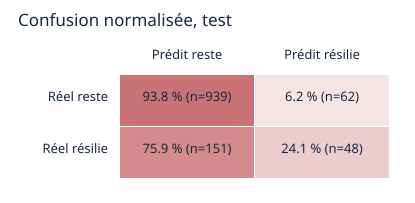

FP 62 | FN 151 | erreur globale 17.7 %.


In [4]:
static void HeatMapMl(string title, string[] x, string[] y, double[, ] v, string[, ] annotations, double scale, (int Column, int FirstRow, int Rows)? border = null)
{
    const int tileW = 135, tileH = 52, left = 120, top = 75;
    int width = left + x.Length * tileW + 25, height = top + y.Length * tileH + 24;
    var svg = new StringBuilder();
    static string E(string text) => SecurityElement.Escape(text)!;
    svg.Append($"<svg xmlns='http://www.w3.org/2000/svg' role='img' aria-label='{E(title)}' viewBox='0 0 {width} {height}' width='{width}'><rect width='100%' height='100%' fill='white'/>");
    svg.Append($"<g font-family='system-ui,sans-serif' font-size='13' fill='#172742'><text x='18' y='26' font-size='17'>{E(title)}</text>");
    for (int col = 0; col < x.Length; col++)
        svg.Append($"<text x='{left + tileW * col + tileW / 2}' y='59' text-anchor='middle'>{E(x[col])}</text>");
    for (int row = 0; row < y.Length; row++)
    {
        int py = top + row * tileH;
        svg.Append($"<text x='{left - 12}' y='{py + tileH / 2}' text-anchor='end'>{E(y[row])}</text>");
        for (int col = 0; col < x.Length; col++)
        {
            // La couleur encode le taux, l’étiquette fournit aussi le dénominateur.
            double intensity = Math.Clamp(v[row, col] / scale, 0, 1);
            int px = left + col * tileW;
            svg.Append($"<rect x='{px}' y='{py}' width='{tileW - 1}' height='{tileH - 1}' fill='#b9464b' fill-opacity='{.10 + .70 * intensity:F3}'/>");
            svg.Append($"<text x='{px + tileW / 2}' y='{py + tileH / 2}' text-anchor='middle'>{E(annotations[row, col])}</text>");
        }
    }

    if (border is { } b)
        svg.Append($"<rect x='{left + b.Column * tileW}' y='{top + b.FirstRow * tileH}' width='{tileW - 1}' height='{b.Rows * tileH - 1}' fill='none' stroke='#005f73' stroke-width='3'/>");
    svg.Append("</g></svg>");
    display(new MlFigure(svg.ToString()));
}

var confusion = Confusion(holdout.Y, predictions.Prediction);
var relative = new double[2, 2];
var text = new string[2, 2];
for (int row = 0; row < 2; row++)
{
    for (int col = 0; col < 2; col++)
    {
        relative[row, col] = confusion[row, col] / (double)(confusion[row, 0] + confusion[row, 1]);
        text[row, col] = $"{relative[row, col]:P1} (n={confusion[row, col]})";
    }
}

HeatMapMl("Confusion normalisée, test", ["Prédit reste", "Prédit résilie"], ["Réel reste", "Réel résilie"], relative, text, 1);
Console.WriteLine($"FP {confusion[0, 1]} | FN {confusion[1, 0]} | erreur globale {1 - Accuracy(holdout.Y, predictions.Prediction):P1}.");

### Lecture de la confusion

Le test compte 62 fausses alertes et 151 résiliations manquées. La normalisation rend les deux lignes comparables malgré des proportions différentes. Le type d’erreur dominant au total peut toutefois être différent de celui qui décrit la poche locale. La confusion doit guider l’inspection sans lui imposer une conclusion.

## 4. Couper par âge et région

On définit cinq tranches d’âge de dix ans et quatre régions. Le taux d’erreur d’une cellule ne s’interprète qu’avec son effectif. L’encadré repère les deux tranches hautes du Nord. Il s’agit d’une première indication, qu’on recoupe ensuite avec la confiance, les contacts et l’historique d’étiquetage.

65–75 |   Est | 13.1 % n=61


45–54 |  Nord | 20.0 % n=45


65–75 |  Nord | 48.5 % n=68


35–44 |   Sud | 13.6 % n=66


35–44 |   Est | 11.3 % n=62


55–64 |   Est | 5.6 % n=54


... (10 outputs left out)

25–34 |   Sud | 11.8 % n=76


45–54 |   Est | 13.7 % n=51


65–75 | Ouest | 19.2 % n=78


35–44 | Ouest | 15.1 % n=53


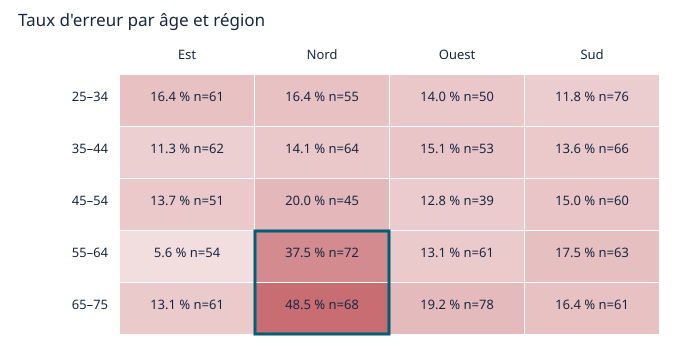

In [5]:
string[] ages = ["25–34", "35–44", "45–54", "55–64", "65–75"];
string[] sortedRegions = ["Est", "Nord", "Ouest", "Sud"];
var error = holdout.Y.Zip(predictions.Prediction, (y, p) => y != p).ToArray();
var groups = Enumerable.Range(0, test.Length).GroupBy(i => (Age: (int)((test[i].Age - 25) / 10), Region: Array.IndexOf(sortedRegions, test[i].Region))).ToDictionary(g => g.Key, g => g.ToArray());
var errorMap = new double[ages.Length, sortedRegions.Length];
var groupText = new string[ages.Length, sortedRegions.Length];
foreach (var(key, members)in groups)
{
    // Garder le nombre d'observations avec chaque taux évite de surlire une case de faible effectif.
    errorMap[key.Age, key.Region] = members.Count(i => error[i]) / (double)members.Length;
    groupText[key.Age, key.Region] = $"{errorMap[key.Age, key.Region]:P1} n={members.Length}";
    Console.WriteLine($"{ages[key.Age], 5} | {sortedRegions[key.Region], 5} | {groupText[key.Age, key.Region]}");
}

RequireMl(groups.Values.Sum(rows => rows.Length) == test.Length && groups.Count == 20, "Il faut classer chacun des clients dans une seule tranche.");
HeatMapMl("Taux d'erreur par âge et région", sortedRegions, ages, errorMap, groupText, .5, (1, 3, 2));

### Lecture de la carte

Les deux tranches âgées du Nord affichent 37,5 % et 48,5 % d’erreurs avec 72 et 68 clients. Les taux sont à comparer à des cellules d’effectifs similaires. Cette carte ne révèle pas encore le mécanisme. Croiser une troisième variable, notamment les contacts, peut expliquer pourquoi seules certaines lignes de ces tranches sont affectées.

### Exercice 1 — Une dimension différente

Coupez l’usage en terciles, calculez les taux d’erreur et les effectifs, puis indiquez la tranche la plus fragile. Comparez votre conclusion à celle de la carte âge/région.

In [6]:
#nullable enable
static (string Tranche, int Nombre, double Erreur)[]? GrouperParUsage(Customer[] clients, bool[] erreurs)
{
    // TODO étudiant : construire trois groupes disjoints et compter les erreurs de chacun.
    return null;
}

var usageGroups = GrouperParUsage(test, error);
if (usageGroups is not null)
{
    RequireMl(usageGroups.Length == 3 && usageGroups.Sum(g => g.Nombre) == test.Length, "Trois groupes doivent couvrir le test.");
    foreach (var g in usageGroups)
        Console.WriteLine($"{g.Tranche} | n={g.Nombre} | erreur {g.Erreur:P1}");
}
else
    Console.WriteLine("À compléter : compter et comparer les trois terciles d’usage.");

À compléter : compter et comparer les trois terciles d’usage.


## 5. Les prédictions incorrectes les plus affirmées

On trie séparément faux négatifs et faux positifs par confiance dans la classe effectivement prédite. Les deux tableaux permettent de comparer la signature « Nord, 55 ans ou plus, au moins deux contacts ». L’entretien avec les équipes qui produisent les données s’appuie ensuite sur cette description, pas sur la seule moyenne d’erreur.

In [7]:
record Assessment(Customer Customer, int Predicted, double ChurnProbability)
{
    public bool Error => Predicted != Customer.Churn;
    public double Confidence => Predicted == 1 ? ChurnProbability : 1 - ChurnProbability;
}

var assessed = test.Select((c, i) => new Assessment(c, predictions.Prediction[i], predictions.Probability[i])).ToArray();
static void PrintAssessment(string title, Assessment[] rows)
{
    Console.WriteLine(title);
    foreach (var item in rows)
    {
        var c = item.Customer;
        Console.WriteLine($"{c.Age, 5:F1} ans | {c.Region, 5} | revenu {c.Income:F0} | usage {c.Usage:F1} | ancienneté {c.Tenure:F1} | contacts {c.Support} | vrai {c.Churn} | prédit {item.Predicted} | P(résil.) {item.ChurnProbability:F3} | confiance {item.Confidence:F3}");
    }
}

foreach (int type in new[]
{
    1,
    0
}

)
{
    // Les ex æquo gardent l'ordre initial de l'ensemble de test comme dans le tri stable source.
    Assessment[] worst = assessed.Where(a => a.Error && a.Customer.Churn == type).OrderByDescending(a => a.Confidence).Take(5).ToArray();
    PrintAssessment(type == 1 ? "Cinq résiliations manquées les plus affirmées" : "Cinq fausses alertes les plus affirmées", worst);
    Console.WriteLine($"Signature de la poche : {worst.Count(a => a.Customer.AuditSlice)}/{worst.Length}.");
}

Cinq résiliations manquées les plus affirmées


 71.7 ans | Ouest | revenu 2948 | usage 51.1 | ancienneté 97.4 | contacts 0 | vrai 1 | prédit 0 | P(résil.) 0.014 | confiance 0.986


 29.9 ans | Ouest | revenu 2145 | usage 51.8 | ancienneté 55.5 | contacts 3 | vrai 1 | prédit 0 | P(résil.) 0.020 | confiance 0.980


 65.8 ans | Ouest | revenu 3577 | usage 39.2 | ancienneté 92.1 | contacts 0 | vrai 1 | prédit 0 | P(résil.) 0.024 | confiance 0.976


 74.9 ans |   Est | revenu 2965 | usage 53.2 | ancienneté 59.3 | contacts 0 | vrai 1 | prédit 0 | P(résil.) 0.026 | confiance 0.974


 39.1 ans | Ouest | revenu 3114 | usage 34.4 | ancienneté 68.6 | contacts 3 | vrai 1 | prédit 0 | P(résil.) 0.038 | confiance 0.962


... (4 outputs left out)

 64.9 ans |  Nord | revenu 2597 | usage 54.3 | ancienneté 113.9 | contacts 3 | vrai 0 | prédit 1 | P(résil.) 0.855 | confiance 0.855


 71.0 ans |  Nord | revenu 3825 | usage 50.3 | ancienneté 29.5 | contacts 3 | vrai 0 | prédit 1 | P(résil.) 0.847 | confiance 0.847


 65.9 ans |  Nord | revenu 4072 | usage 57.7 | ancienneté 88.9 | contacts 3 | vrai 0 | prédit 1 | P(résil.) 0.846 | confiance 0.846


Signature de la poche : 5/5.


### Lecture des fausses alertes

Les cinq fausses alertes les plus affirmées correspondent à la signature de la poche, contre aucune des cinq résiliations manquées. Une erreur à confiance haute a franchi le seuil avec marge. Le rapprochement de plusieurs lignes de ce type permet de chercher une signature commune. Les cinq lignes triées ne sont pas un échantillon aléatoire et ne donnent pas seules la fréquence de la cause.

L’exercice 2, dans la dernière partie du carnet, reprend ce tri en mélangeant les deux types d’erreurs.

## 6. Erreur et confiance

La confiance d’une prédiction positive est sa probabilité de résiliation. Pour une prédiction négative, on utilise le complément. On compare les distributions des décisions exactes et erronées, puis on compte les erreurs fortement affirmées au-delà de 0,80.

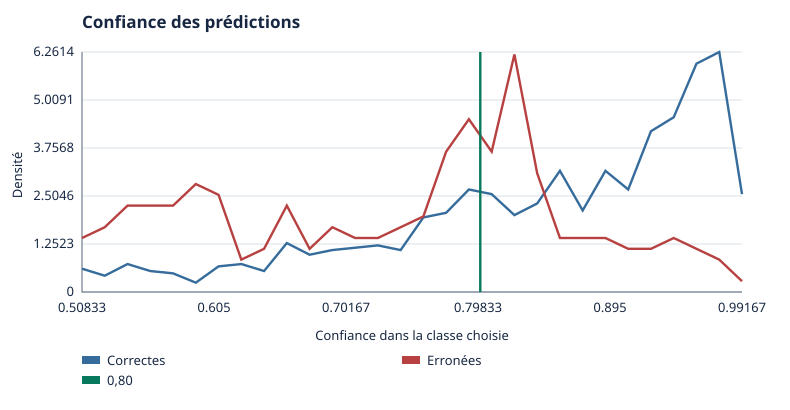

Erreurs à confiance >0,80 : 82/213.


Erreurs de la poche sur test propre : 48, dont 26 à confiance >0,80.


In [8]:
static MlSeries ConfidenceDensity(Assessment[] rows, string label, string colour)
{
    const int bins = 30;
    var counts = new int[bins];
    foreach (var a in rows)
    {
        // Les deux distributions partagent les mêmes classes d’histogramme sur [0,5 ; 1].
        int bin = Math.Clamp((int)((a.Confidence - .5) * 2 * bins), 0, bins - 1);
        counts[bin]++;
    }

    double[] x = Enumerable.Range(0, bins).Select(i => .5 + .5 * (i + .5) / bins).ToArray();
    double[] density = counts.Select(n => n / (rows.Length * .5 / bins)).ToArray();
    return new MlSeries(label, colour, x, density);
}

var incorrect = assessed.Where(a => a.Error).ToArray();
var correct = assessed.Where(a => !a.Error).ToArray();
var goodCurve = ConfidenceDensity(correct, "Correctes", "#356c9c");
var badCurve = ConfidenceDensity(incorrect, "Erronées", "#b74040");
PlotMl("Confiance des prédictions", "Confiance dans la classe choisie", "Densité", goodCurve, badCurve, new MlSeries("0,80", "#08795c", [.8, .8], [0, Math.Max(goodCurve.Y.Max(), badCurve.Y.Max())]));
Console.WriteLine($"Erreurs à confiance >0,80 : {incorrect.Count(a => a.Confidence > .80)}/{incorrect.Length}.");
var pocketErrors = incorrect.Where(a => a.Customer.AuditSlice).ToArray();
Console.WriteLine($"Erreurs de la poche sur test propre : {pocketErrors.Length}, dont {pocketErrors.Count(a => a.Confidence > .8)} à confiance >0,80.");

### Lecture des erreurs très affirmées

Le tableau compte 26 erreurs à confiance supérieure à 0,80 dans la poche. Les erreurs de proximité au seuil restent compatibles avec un signal imparfait. Des erreurs très affirmées dans une tranche identifiable suggèrent un problème distinct. Ici, la simulation permet de vérifier l’explication par la qualité des étiquettes du train.

## 7. Augmenter la capacité laisse le défaut en place

On passe à 1 000 arbres sans profondeur maximale et à des feuilles d’au moins une observation. Le train corrompu et le test restent identiques. Cette intervention exerce une capacité supplémentaire sans introduire d’information correcte sur la tranche.

In [9]:
static (double Global, double Pocket, double Outside) ErrorRates(Customer[] customers, int[] prediction)
{
    var paired = customers.Zip(prediction, (c, p) => (c.AuditSlice, Error: c.Churn == p ? 0.0 : 1.0)).ToArray();
    return (paired.Average(x => x.Error), paired.Where(x => x.AuditSlice).Average(x => x.Error), paired.Where(x => !x.AuditSlice).Average(x => x.Error));
}

var largeForest = new ModelConfig("forest", Trees: 1000, Depth: null, MinimumLeaf: 1);
// Seule la capacité change : la population, les étiquettes et le test restent identiques.
var tuned = FitTreeModel(largeForest, corruptedData, holdout);
var startingRates = ErrorRates(test, predictions.Prediction);
var tunedRates = ErrorRates(test, tuned.Prediction);
static void PrintRates(string arm, (double Global, double Pocket, double Outside) r) => Console.WriteLine($"{arm, -22} | globale {r.Global, 7:P1} | poche {r.Pocket, 7:P1} | reste {r.Outside, 7:P1}");
Console.WriteLine($"Poche test : {test.Count(c => c.AuditSlice)} clients sur {test.Length}.");
PrintRates("Référence", startingRates);
PrintRates("Capacité seule", tunedRates);

Poche test : 71 clients sur 1200.


Référence              | globale  17.7 % | poche  67.6 % | reste  14.6 %


Capacité seule         | globale  18.3 % | poche  67.6 % | reste  15.2 %


### Lecture de l’intervention

L’erreur dans la poche reste à 67,6 % alors que l’erreur globale passe de 17,7 % à 18,3 %. Les mêmes étiquettes apprennent au modèle plus flexible la même association erronée. Regardez l’évolution du taux de la poche et celle du reste du portefeuille avant de juger l’augmentation du score global.

## 8. Des indices à une hypothèse vérifiable

| Cause candidate | Action qui la teste | Indice dans cette simulation |
|---|---|---|
| Étiquettes bruitées | Comparer à une source de statuts fiable, corriger les lignes confirmées | Les mêmes contacts, région et tranche d’âge reviennent dans les fausses alertes affirmées. |
| Tranche pauvre en données | Collecter davantage ou pondérer pour un test contrôlé | Les effectifs situent la taille de la poche, mais ne suffisent pas à exclure cette cause. |
| Variable manquante | Identifier puis intégrer la variable qui explique les erreurs | Les lignes inspectées partagent déjà une signature observable. |
| Cas irréductibles | Examiner les erreurs autour du seuil et la limite de séparabilité | Le faible signal peut expliquer des erreurs hésitantes ailleurs. |

L’intervention suivante corrige une cause dont la simulation connaît la vérité. Un audit métier aurait besoin d’une vérification externe des étiquettes.

In [10]:
// Quantifier le sous-ensemble large et la poche plus précise.
int olderNorthern = train.Count(c => c.Region == "Nord" && c.Age >= 55);
Console.WriteLine($"Train : {olderNorthern} seniors du Nord ; {overwritten} dans la poche à deux contacts ou plus, dont {changed} étiquettes à restaurer.");

Train : 273 seniors du Nord ; 115 dans la poche à deux contacts ou plus, dont 91 étiquettes à restaurer.


## 9. Ré-auditer les étiquettes puis mesurer le gain

On restaure la vérité dans la poche du train uniquement, et on garde les hyperparamètres de référence. L’écart dans la poche mesure l’effet ciblé. L’écart hors poche permet de vérifier si la correction dégrade la population restante.

In [11]:
var audited = corrupted.Zip(train, (noisy, original) => original.AuditSlice ? noisy with { Churn = original.Churn } : noisy).ToArray();
RequireMl(audited.SequenceEqual(train), "L'audit doit restaurer les étiquettes originales sans autre modification.");
var after = FitTreeModel(baseline, ToData(audited), holdout);
var auditedRates = ErrorRates(test, after.Prediction);
PrintRates("Train corrompu", startingRates);
PrintRates("Train ré-audité", auditedRates);
// Mesurer en points de pourcentage sur exactement les mêmes personnes.
Console.WriteLine($"Variation poche {(auditedRates.Pocket - startingRates.Pocket) * 100:+0.0;-0.0;0.0} points | globale {(auditedRates.Global - startingRates.Global) * 100:+0.0;-0.0;0.0} | reste {(auditedRates.Outside - startingRates.Outside) * 100:+0.0;-0.0;0.0}.");

Train corrompu         | globale  17.7 % | poche  67.6 % | reste  14.6 %


Train ré-audité        | globale  15.9 % | poche  25.4 % | reste  15.3 %


Variation poche -42.3 points | globale -1.8 | reste +0.7.


### Lecture de l’audit

Le ré-audit ramène l’erreur locale de 67,6 % à 25,4 %. Hors poche, elle passe de 14,6 % à 15,3 %, ce qui borne l’interprétation du gain. Le bras ré-audité change la supervision et le bras capacité change l’estimateur. Cette séparation permet d’attribuer les écarts de la poche à l’intervention sur les données dans ce monde contrôlé.

### Exercice 2 — Changer le tri

Extrayez les cinq erreurs de plus forte confiance en mélangeant les deux types. Comparez ce classement à la sélection séparée par type, puis expliquez quelle mesure rend une poche plus visible.

In [12]:
#nullable enable
static Assessment[]? TrierCinqErreurs(Assessment[] résultats)
{
    // TODO étudiant : établir le tri par confiance dans la classe erronée.
    return null;
}

var topFive = TrierCinqErreurs(assessed);
if (topFive is not null)
{
    RequireMl(topFive.Length == 5 && topFive.All(a => a.Error), "Le tableau doit contenir cinq erreurs.");
    PrintAssessment("Erreurs affirmées tous types", topFive);
}
else
    Console.WriteLine("À compléter : comparer tri global et tri par type.");

À compléter : comparer tri global et tri par type.


### Exercice 3 — Pondérer au lieu de ré-auditer

Augmentez le poids des lignes de la poche dans le train corrompu. Utilisez le paramètre de poids du même estimateur. Évaluez le comparatif global, poche et reste sur le même test et expliquez ce qui se passe lorsqu’on amplifie une supervision bruitée.

In [13]:
#nullable enable
static double[]? PondérationsDePoche(Customer[] clients, double facteur)
{
    // TODO étudiant : produire un poids par ligne dans l'ordre du train.
    return null;
}

var weights = PondérationsDePoche(corrupted, 3);
if (weights is not null)
{
    RequireMl(weights.Length == corrupted.Length && weights.All(w => double.IsFinite(w) && w > 0), "Poids strictement positifs et appariés requis.");
    var weighted = FitTreeModel(baseline, corruptedData, holdout, weights);
    PrintRates("Référence pondérée", ErrorRates(test, weighted.Prediction));
    PrintRates("Ré-audit", auditedRates);
}
else
    Console.WriteLine("À compléter : pondérer les lignes de la poche et comparer sur le test intact.");

À compléter : pondérer les lignes de la poche et comparer sur le test intact.


## À retenir

- Définissez le type d’erreur dans les unités de la décision, puis regardez la confusion par classe.
- Utilisez des taux par tranche avec leurs effectifs. Inspectez les erreurs affirmées pour formuler une hypothèse précise.
- Fixez le test et modifiez une seule famille de causes à la fois.

## Vérifiez votre compréhension

**Pourquoi le score global peut-il rester stable après un échec local ?**

<details><summary>Réponse</summary>

Une petite tranche contribue peu à la moyenne globale. Le taux conditionnel et le nombre d’exemples dans cette tranche isolent un échec que le score agrégé dilue.

</details>

**Quel contrôle permet d’attribuer l’amélioration au ré-audit ?**

<details><summary>Réponse</summary>

Il faut conserver estimateur, paramètres et ensemble de test, puis vérifier que les seules modifications touchent les étiquettes validées du train. Le bras de capacité répond à une autre question.

</details>

## Pour aller plus loin

- [Biais, variance et découpage](2.5-Biais-Variance-CV-ROC-CSharp.ipynb).
- [Équité par sous-groupes](2.5c-Equite-Sous-Groupes-CSharp.ipynb).
- [API scikit-learn de la forêt aléatoire](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).